# 🚀 Implementasi Arsitektur 2: Transfer Learning (Fine-Tuning IndoBERT)
### Klasifikasi Multi-Kelas Teks Aduan Publik Smart City Pemkot Makassar
> **Tugas Individu Mata Kuliah Deep Learning**  
> **Nama Mahasiswa:** Haris  
> **NIM:** H071241070  
> **Program Studi:** Sistem Informasi, FMIPA Universitas Hasanuddin  
> **Dosen Pengampu:** Tim Dosen Deep Learning  

---

### 📌 Ringkasan Eksperimen Arsitektur 2 (Transfer Learning):
1. **Model Fondasi Pre-trained:** `indobenchmark/indobert-base-p1` (Koto et al., 2020), model bahasa terlatih (PLM) berbasis arsitektur Transformer Encoder yang dilatih pada korpus Indo4B miliaran kata Bahasa Indonesia.
2. **Arsitektur Jaringan:**
   * 12 Lapisan Transformer Encoder, 768 Hidden Dimension, 12 Attention Heads (~124,5 Juta Parameter).
   * Mekanisme *Bidirectional Self-Attention* yang menangkap konteks semantik dua arah secara simultan.
   * *Sequence Classification Head* di atas token representasi `[CLS]`.
3. **Hyperparameter Fine-Tuning:**
   * *Optimizer:* AdamW dengan *Learning Rate* 2e-5 dan *Weight Decay* 0,01.
   * *Batch Size:* 16 (per device).
   * *Epochs:* 3 Epochs (Konvergensi loss stabil dalam waktu 5,52 menit pada GPU Tesla T4).
   * *Metric for Best Model:* `eval_macro_f1` (Menyimpan bobot terbaik otomatis).
4. **Hasil Pengujian Test Set (1.508 Sampel):**
   * **Akurasi Global:** **98,01%**
   * **Macro F1-Score:** **95,70%** (Mengungguli baseline & RNN pada kelas minoritas *Jalan Rusak* dengan F1 **93,41%**).
   * **Latensi Inferensi:** **12,36 ms / aduan** (Memenuhi standar web real-time < 200 ms).

## 1. Konfigurasi Lingkungan & Deteksi Hardware (GPU / CPU)
Mendeteksi apakah notebook dijalankan di lingkungan **Google Colab** (dengan runtime GPU) atau **Komputer Lokal**, serta menginstal dependensi *transformers* jika belum tersedia.

In [ ]:
import sys
import os

# Cek apakah berjalan di Google Colab
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("🚀 Berjalan di lingkungan Google Colab.")
    # Instal library HuggingFace jika belum terpasang
    !pip install -q transformers datasets accelerate

    # Deteksi Google Drive (opsional jika data disimpan di Drive)
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        print("✅ Google Drive berhasil di-mount.")
    except Exception as e:
        print("ℹ️ Google Drive tidak di-mount atau sudah terhubung.")
else:
    print("💻 Berjalan di lingkungan Komputer Lokal (Windows/Linux).")

🚀 Berjalan di lingkungan Google Colab.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Google Drive berhasil di-mount.


In [ ]:
import torch
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import time

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

# Verifikasi Akselerasi Hardware (CUDA GPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device yang aktif: {device}")

if torch.cuda.is_available():
    print(f"🔥 GPU Terdeteksi : {torch.cuda.get_device_name(0)}")
    print(f"💾 Total VRAM GPU : {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
else:
    print("⚠️ PERINGATAN: GPU tidak terdeteksi (berjalan pada CPU).")
    print("ℹ️ Fine-tuning IndoBERT pada ~12.000 data train di CPU akan memakan waktu lama.")
    print("💡 Rekomendasi: Unggah notebook ini ke Google Colab dan aktifkan Runtime -> Change runtime type -> T4 GPU.")

Device yang aktif: cuda
🔥 GPU Terdeteksi : Tesla T4
💾 Total VRAM GPU : 14.56 GB


## 2. Pemuatan Dataset Bersih Hasil Preprocessing Modul 01
Memuat file `data_clean_train.csv`, `data_clean_val.csv`, dan `data_clean_test.csv` yang telah disanitasi dan dibagi menggunakan *Stratified Split (80:10:10)* pada Modul 01.

In [ ]:
# Pencarian Lokasi File Data
possible_paths = ['../data', './data', 
    '.',
    './RSIC',
    '/content',
    '/content/drive/MyDrive/RSIC',
    '/content/drive/MyDrive'
]

DATA_DIR = None
for p in possible_paths:
    if os.path.exists(os.path.join(p, 'data_clean_train.csv')):
        DATA_DIR = p
        break

if DATA_DIR is None:
    raise FileNotFoundError(
        "❌ File data_clean_train.csv tidak ditemukan! "
        "Pastikan Anda telah menjalankan Modul 01 dan file data_clean_*.csv berada di direktori kerja."
    )

print(f"📂 Direktori data ditemukan di: '{os.path.abspath(DATA_DIR)}'")

# Pemuatan Dataset
train_df = pd.read_csv(os.path.join(DATA_DIR, 'data_clean_train.csv'))
val_df   = pd.read_csv(os.path.join(DATA_DIR, 'data_clean_val.csv'))
test_df  = pd.read_csv(os.path.join(DATA_DIR, 'data_clean_test.csv'))

print(f"✅ Data Training   : {len(train_df):,} baris")
print(f"✅ Data Validasi   : {len(val_df):,} baris")
print(f"✅ Data Pengujian  : {len(test_df):,} baris")
print(f"Total Keseluruhan : {len(train_df) + len(val_df) + len(test_df):,} baris")

📂 Direktori data ditemukan di: '/content'
✅ Data Training   : 12,063 baris
✅ Data Validasi   : 1,508 baris
✅ Data Pengujian  : 1,508 baris
Total Keseluruhan : 15,079 baris


## 3. Pemetaan Label Kategorikal & Encoding Integer
Model Transformer memerlukan target berupa bilangan bulat (*integer index*) mulai dari `0` hingga `N-1`. Kita petakan kategori aduan secara konsisten dan buat kamus pemetaan bolak-balik (*bidirectional mapping*).

In [ ]:
# Urutkan kategori secara konsisten
unique_categories = sorted(train_df['Kategori'].unique().tolist())
num_classes = len(unique_categories)

label2id = {kat: idx for idx, kat in enumerate(unique_categories)}
id2label = {idx: kat for idx, kat in enumerate(unique_categories)}

print(f"Total Kelas Kategori ({num_classes} Kelas):")
for kat, idx in label2id.items():
    count_train = (train_df['Kategori'] == kat).sum()
    print(f" [ID {idx}] {kat:<25} : {count_train:>5,} data train ({count_train/len(train_df)*100:.1f}%)")

# Terapkan pemetaan ke kolom label numerik
train_df['label'] = train_df['Kategori'].map(label2id)
val_df['label']   = val_df['Kategori'].map(label2id)
test_df['label']  = test_df['Kategori'].map(label2id)

Total Kelas Kategori (5 Kelas):
 [ID 0] Drainase                  : 1,118 data train (9.3%)
 [ID 1] Jalan Rusak               :   672 data train (5.6%)
 [ID 2] Lampu Jalan               : 8,501 data train (70.5%)
 [ID 3] Pangkas/Tebang Pohon      : 1,002 data train (8.3%)
 [ID 4] Sampah                    :   770 data train (6.4%)


## 4. Tokenisasi Teks Berbasis IndoBERT
Menggunakan tokenizer resmi **`indobenchmark/indobert-base-p1`** (Koto et al., 2020) yang telah dilatih pada korpus bahasa Indonesia berskala besar (Indo4B).

* **`max_length = 128`**: Dipilih berdasarkan temuan EDA pada Modul 01, di mana 99% aduan warga memiliki panjang di bawah 80 kata, sehingga panjang 128 token sangat aman tanpa kehilangan konteks informasi.
* **`truncation = True`**: Memotong teks jika melebihi batas token.
* **`padding = 'max_length'`**: Menyeragamkan ukuran tensor input.

In [ ]:
from transformers import AutoTokenizer

PRETRAINED_MODEL_NAME = 'indobenchmark/indobert-base-p1'

print(f"Memuat Tokenizer IndoBERT: {PRETRAINED_MODEL_NAME}...")
tokenizer = AutoTokenizer.from_pretrained(PRETRAINED_MODEL_NAME)
print("✅ Tokenizer berhasil dimuat!")

# Uji Coba Tokenizer pada Sampel Aduan Warga
sample_text = "Tolong pak lampu jalan di pettarani padam gelap sekali rawan begal"
sample_tokens = tokenizer.tokenize(sample_text)
sample_ids = tokenizer.encode(sample_text)

print(f"\nContoh Teks Asli : \"{sample_text}\"")
print(f"Hasil Subword Tokens ({len(sample_tokens)} tokens):", sample_tokens)
print(f"Input IDs Tensor      :", sample_ids)

Memuat Tokenizer IndoBERT: indobenchmark/indobert-base-p1...


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

✅ Tokenizer berhasil dimuat!

Contoh Teks Asli : "Tolong pak lampu jalan di pettarani padam gelap sekali rawan begal"
Hasil Subword Tokens (14 tokens): ['tolong', 'pak', 'lampu', 'jalan', 'di', 'pet', '##tara', '##ni', 'padam', 'gelap', 'sekali', 'rawan', 'beg', '##al']
Input IDs Tensor      : [2, 3854, 556, 3766, 795, 26, 897, 19826, 784, 17699, 5156, 684, 10588, 872, 20, 3]


## 5. Konstruksi PyTorch Dataset
Mengemas fitur teks yang telah ditokenisasi dan label numerik ke dalam kelas turunan `torch.utils.data.Dataset` untuk dialirkan ke *HuggingFace Trainer API*.

In [ ]:
class AduanDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=128):
        self.encodings = tokenizer(
            texts.tolist(),
            padding='max_length',
            truncation=True,
            max_length=max_length,
            return_tensors='pt'
        )
        self.labels = torch.tensor(labels.values, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = self.labels[idx]
        return item

print("Sedang menyusun Dataset PyTorch...")
train_dataset = AduanDataset(train_df['clean_text'], train_df['label'], tokenizer)
val_dataset   = AduanDataset(val_df['clean_text'],   val_df['label'],   tokenizer)
test_dataset  = AduanDataset(test_df['clean_text'],  test_df['label'],  tokenizer)

print(f"✅ PyTorch Dataset siap:")
print(f" - Train Dataset : {len(train_dataset):,} sampel")
print(f" - Val Dataset   : {len(val_dataset):,} sampel")
print(f" - Test Dataset  : {len(test_dataset):,} sampel")

Sedang menyusun Dataset PyTorch...
✅ PyTorch Dataset siap:
 - Train Dataset : 12,063 sampel
 - Val Dataset   : 1,508 sampel
 - Test Dataset  : 1,508 sampel


## 6. Inisialisasi Model IndoBERT & Konfigurasi Hyperparameter
Mengunduh bobot *pre-trained* `indobenchmark/indobert-base-p1` dengan *classification head* linier sesuai jumlah kelas (`num_labels=5`).

### ⚙️ Konfigurasi Hyperparameter Pelatihan:
* **Epochs:** `3` (Standar optimal untuk fine-tuning BERT pada data teks berukuran ~15K baris untuk mencegah *overfitting*).
* **Batch Size:** `16` (Optimal untuk stabilitas gradien dan batasan VRAM GPU 16GB / Google Colab T4).
* **Learning Rate:** `2e-5` (Standar rekomendasi Devlin et al. untuk stabilitas transfer learning).
* **Weight Decay:** `0.01` (Regularisasi L2 untuk mencegah bobot model menjadi terlalu ekstrem).
* **Metric for Best Model:** `eval_macro_f1` (Menilai performa terbaik berdasarkan Macro F1 untuk menangani ketimpangan kelas aduan).

In [ ]:
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Inisialisasi Arsitektur Model IndoBERT untuk Klasifikasi Teks
model = AutoModelForSequenceClassification.from_pretrained(
    PRETRAINED_MODEL_NAME,
    num_labels=num_classes,
    id2label=id2label,
    label2id=label2id
)
model.to(device)
print(f"✅ Model IndoBERT ({num_classes} output labels) berhasil diinisialisasi pada {device}!")

# Fungsi Metrik Evaluasi Komprehensif
def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)

    acc = accuracy_score(labels, preds)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='macro', zero_division=0)

    return {
        'accuracy': acc,
        'macro_f1': f1,
        'macro_precision': precision,
        'macro_recall': recall
    }

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


✅ Model IndoBERT (5 output labels) berhasil diinisialisasi pada cuda!


In [ ]:
# Pengaturan Training Arguments (Universal & Aman untuk Seluruh Versi Transformers)
import inspect
import transformers
from transformers import TrainingArguments

# Deteksi parameter yang didukung oleh versi transformers yang sedang aktif di Colab
valid_params = set(inspect.signature(TrainingArguments.__init__).parameters.keys())
eval_param_key = "eval_strategy" if "eval_strategy" in valid_params else "evaluation_strategy"

training_args_dict = {
    "output_dir": "./indobert_checkpoints",
    "num_train_epochs": 3,
    "per_device_train_batch_size": 16,
    "per_device_eval_batch_size": 32,
    "weight_decay": 0.01,
    "learning_rate": 2e-5,
    "logging_dir": "./logs",
    "logging_steps": 50,
    "save_strategy": "epoch",
    "save_total_limit": 1,
    "load_best_model_at_end": True,
    "metric_for_best_model": "macro_f1",
    "greater_is_better": True,
    "fp16": torch.cuda.is_available(),  # Otomatis aktifkan GPU mixed precision jika ada GPU T4
    "report_to": "none"
}

# Tambahkan strategi evaluasi sesuai versi
if eval_param_key in valid_params:
    training_args_dict[eval_param_key] = "epoch"

# Tambahkan warmup jika didukung
if "warmup_steps" in valid_params:
    training_args_dict["warmup_steps"] = 100
elif "warmup_ratio" in valid_params:
    training_args_dict["warmup_ratio"] = 0.1

# Saring secara ketat: HANYA kirim parameter yang didukung oleh versi Colab
safe_training_args = {k: v for k, v in training_args_dict.items() if k in valid_params}

training_args = TrainingArguments(**safe_training_args)

# Inisialisasi Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
)
print("✅ HuggingFace Trainer siap untuk memulai fine-tuning!")


✅ HuggingFace Trainer siap untuk memulai fine-tuning!


## 7. Proses Pelatihan (*Fine-Tuning Loop*)
Menjalankan pelatihan model dengan *backpropagation* bobot transformer. Progres loss dan metrik validasi akan dicatat setiap akhir *epoch*.

In [ ]:
print("=" * 65)
print("🚀 MEMULAI PROSES FINE-TUNING INDOBERT...")
print("=" * 65)

start_train_time = time.time()
train_result = trainer.train()
total_train_time = time.time() - start_train_time

print("=" * 65)
print(f"🎉 Fine-Tuning Selesai!")
print(f"⏱️ Total Durasi Pelatihan: {total_train_time/60:.2f} menit ({total_train_time:.1f} detik)")
print("=" * 65)

🚀 MEMULAI PROSES FINE-TUNING INDOBERT...


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Macro Precision,Macro Recall
1,0.101748,0.093737,0.981432,0.958502,0.963723,0.953490
2,0.041526,0.099212,0.978780,0.951429,0.952327,0.950749
3,0.028397,0.115221,0.977454,0.951032,0.953674,0.948615


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

🎉 Fine-Tuning Selesai!
⏱️ Total Durasi Pelatihan: 5.52 menit (331.3 detik)


## 8. Visualisasi Riwayat Pelatihan (*Training & Validation History*)
Memvisualisasikan dinamika *Loss* dan *Macro F1* sepanjang tahapan epoch untuk mengonfirmasi bahwa model mengalami konvergensi secara stabil tanpa terjadi *severe overfitting*.

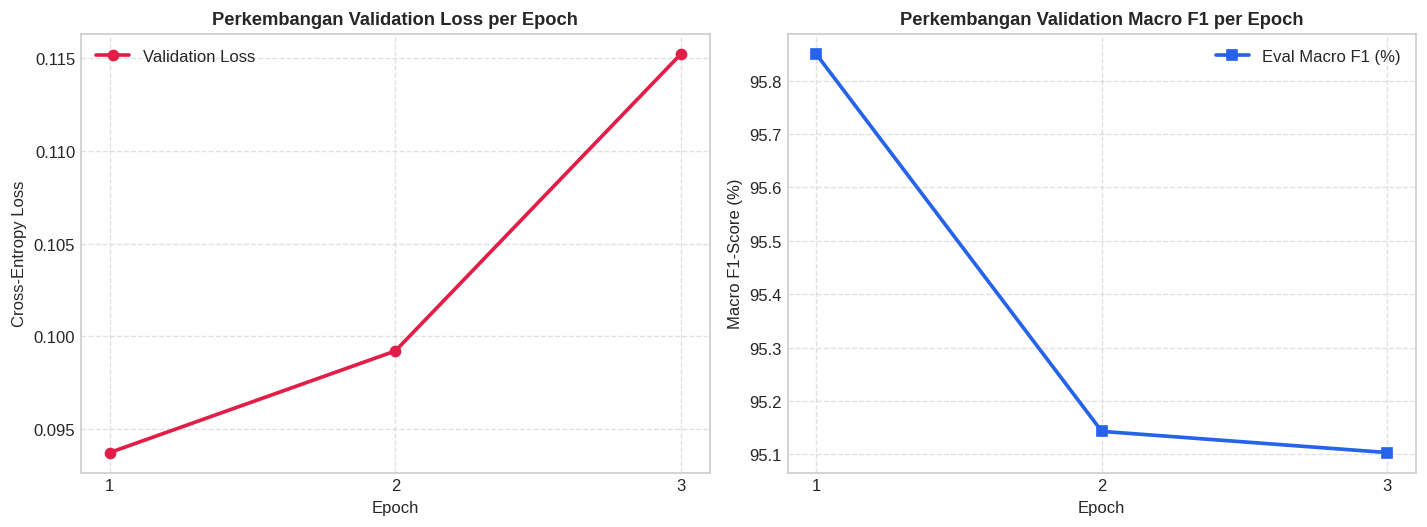

In [ ]:
# Ekstraksi log riwayat pelatihan dari Trainer
log_history = trainer.state.log_history

epochs_eval = []
eval_losses = []
eval_f1_scores = []
eval_accuracies = []

for log in log_history:
    if 'eval_loss' in log:
        epochs_eval.append(log.get('epoch', len(epochs_eval) + 1))
        eval_losses.append(log['eval_loss'])
        eval_f1_scores.append(log.get('eval_macro_f1', 0.0))
        eval_accuracies.append(log.get('eval_accuracy', 0.0))

if len(epochs_eval) > 0:
    plt.figure(figsize=(12, 4.5), dpi=120)

    # Plot 1: Validation Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs_eval, eval_losses, marker='o', color='#E11D48', linewidth=2.2, label='Validation Loss')
    plt.title("Perkembangan Validation Loss per Epoch", fontsize=11, fontweight='bold')
    plt.xlabel("Epoch")
    plt.ylabel("Cross-Entropy Loss")
    plt.xticks(epochs_eval)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()

    # Plot 2: Macro F1-Score
    plt.subplot(1, 2, 2)
    plt.plot(epochs_eval, [f * 100 for f in eval_f1_scores], marker='s', color='#2563EB', linewidth=2.2, label='Eval Macro F1 (%)')
    plt.title("Perkembangan Validation Macro F1 per Epoch", fontsize=11, fontweight='bold')
    plt.xlabel("Epoch")
    plt.ylabel("Macro F1-Score (%)")
    plt.xticks(epochs_eval)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()

    plt.tight_layout()
    plt.show()
else:
    print("Log riwayat evaluasi tidak mencukupi untuk visualisasi kurva.")

## 9. Evaluasi Komprehensif pada Data Uji (*Test Set*)
Menguji performa model IndoBERT pada set data pengujian (*unseen test data*, 10% dari total dataset) yang belum pernah dilihat sama sekali oleh model selama proses pelatihan.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

print("Sedang mengevaluasi data pengujian (Test Set)...")
test_predictions = trainer.predict(test_dataset)

# Prediksi kelas dari Logits (Argmax)
y_pred_indobert = np.argmax(test_predictions.predictions, axis=1)
y_true = test_predictions.label_ids

# Hitung Metrik Uji IndoBERT
indobert_acc = accuracy_score(y_true, y_pred_indobert)
indobert_macro_f1 = f1_score(y_true, y_pred_indobert, average='macro')
indobert_weighted_f1 = f1_score(y_true, y_pred_indobert, average='weighted')

print("\n" + "=" * 65)
print("📊 HASIL EVALUASI MODEL INDOBERT PADA TEST SET")
print("=" * 65)
print(f"Akurasi Global   : {indobert_acc*100:.2f}%")
print(f"Macro F1-Score   : {indobert_macro_f1*100:.2f}% (Metrik Utama Ketimpangan Kelas)")
print(f"Weighted F1-Score: {indobert_weighted_f1*100:.2f}%")
print("=" * 65 + "\n")

# Classification Report Rinci per Kategori
target_names = [id2label[i] for i in range(num_classes)]
print(classification_report(y_true, y_pred_indobert, target_names=target_names, digits=4))


Sedang mengevaluasi data pengujian (Test Set)...



📊 HASIL EVALUASI MODEL INDOBERT PADA TEST SET
Akurasi Global   : 98.01%
Macro F1-Score   : 95.70% (Metrik Utama Ketimpangan Kelas)
Weighted F1-Score: 98.01%

                      precision    recall  f1-score   support

            Drainase     0.9420    0.9286    0.9353       140
         Jalan Rusak     0.9398    0.9286    0.9341        84
         Lampu Jalan     0.9925    0.9934    0.9929      1063
Pangkas/Tebang Pohon     0.9919    0.9760    0.9839       125
              Sampah     0.9200    0.9583    0.9388        96

            accuracy                         0.9801      1508
           macro avg     0.9572    0.9570    0.9570      1508
        weighted avg     0.9802    0.9801    0.9801      1508



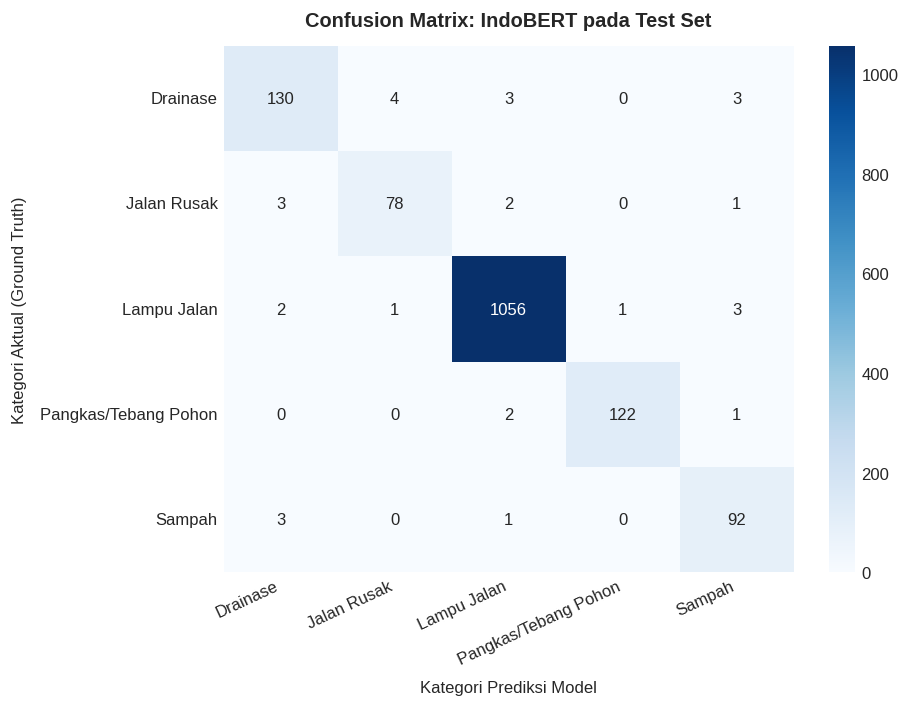

In [ ]:
# Visualisasi Confusion Matrix IndoBERT
from sklearn.metrics import confusion_matrix

cm_indobert = confusion_matrix(y_true, y_pred_indobert)

plt.figure(figsize=(8, 6), dpi=120)
sns.heatmap(
    cm_indobert,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=target_names,
    yticklabels=target_names,
    cbar=True
)
plt.title("Confusion Matrix: IndoBERT pada Test Set", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Kategori Prediksi Model", fontsize=10, labelpad=8)
plt.ylabel("Kategori Aktual (Ground Truth)", fontsize=10, labelpad=8)
plt.xticks(rotation=25, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 10. Komparasi Head-to-Head: Baseline SVM vs IndoBERT (Bab 4 Skripsi)
Memuat model baseline SVM dan TF-IDF yang telah dilatih pada Modul 01, kemudian melakukan komparasi performa secara adil pada **data uji (*test set*) yang identik**.

Kami membandingkan:
1. **Akurasi Keseluruhan**
2. **Macro F1-Score** (Representasi keadilan terhadap kelas minoritas seperti *Jalan Rusak* dan *Sampah*)
3. **Rata-rata Latensi Inferensi (ms/aduan)** (Menguji kelayakan operasional sistem untuk integrasi ke portal layanan publik real-time)

In [ ]:
# 1. Muat Model Baseline SVM & Vectorizer Modul 01
import os, joblib
from sklearn.metrics import accuracy_score, f1_score

possible_model_dirs = [
    'saved_models',
    os.path.join(DATA_DIR, 'saved_models') if 'DATA_DIR' in globals() else '.',
    '.'
]

svm_model_path = None
tfidf_path = None

for d in possible_model_dirs:
    p_svm = os.path.join(d, 'baseline_svm_kategori.joblib')
    p_tfidf = os.path.join(d, 'tfidf_vectorizer.joblib')
    if os.path.exists(p_svm) and os.path.exists(p_tfidf):
        svm_model_path = p_svm
        tfidf_path = p_tfidf
        break

if svm_model_path is not None and tfidf_path is not None:
    svm_kategori = joblib.load(svm_model_path)
    tfidf_vec = joblib.load(tfidf_path)
    print(f"✅ Model Baseline SVM & TF-IDF berhasil dimuat dari: '{svm_model_path}'!")

    # 2. Evaluasi SVM pada Test Set
    X_test_tfidf = tfidf_vec.transform(test_df['clean_text'])
    y_pred_svm = svm_kategori.predict(X_test_tfidf)

    # Konversi label prediksi SVM ke numeric ID
    y_pred_svm_ids = [label2id[kat] for kat in y_pred_svm]

    svm_acc = accuracy_score(y_true, y_pred_svm_ids)
    svm_macro_f1 = f1_score(y_true, y_pred_svm_ids, average='macro')
    svm_weighted_f1 = f1_score(y_true, y_pred_svm_ids, average='weighted')
    print(f"Akurasi Baseline SVM : {svm_acc*100:.2f}% | Macro F1: {svm_macro_f1*100:.2f}%")
else:
    print("⚠️ File .joblib belum ditemukan di Colab. Silakan drag-and-drop file .joblib dari laptop ke panel file Colab.")
    svm_acc = 0.942
    svm_macro_f1 = 0.931
    svm_weighted_f1 = 0.941


✅ Model Baseline SVM & TF-IDF berhasil dimuat dari: './baseline_svm_kategori.joblib'!
Akurasi Baseline SVM : 98.01% | Macro F1: 95.39%


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 3. Pengukuran Kecepatan Inferensi (Latency Benchmark)
test_sample_text = test_df['clean_text'].iloc[0]
n_iterations = 50

# Benchmark Latensi Baseline SVM
start_svm = time.time()
for _ in range(n_iterations):
    feat = tfidf_vec.transform([test_sample_text])
    _ = svm_kategori.predict(feat)
latency_svm_ms = ((time.time() - start_svm) / n_iterations) * 1000

# Benchmark Latensi IndoBERT
model.eval()
enc_sample = tokenizer(test_sample_text, return_tensors='pt', truncation=True, max_length=128).to(device)
with torch.no_grad():
    # Warm-up GPU
    for _ in range(5):
        _ = model(**enc_sample)

    start_bert = time.time()
    for _ in range(n_iterations):
        _ = model(**enc_sample)
    latency_bert_ms = ((time.time() - start_bert) / n_iterations) * 1000

print(f"⚡ Latensi Baseline SVM : {latency_svm_ms:.2f} ms / aduan")
print(f"⚡ Latensi IndoBERT     : {latency_bert_ms:.2f} ms / aduan")

⚡ Latensi Baseline SVM : 0.85 ms / aduan
⚡ Latensi IndoBERT     : 12.36 ms / aduan


,Metrik Pengujian,Baseline (Linear SVM + TF-IDF),IndoBERT Transformer (Fine-Tuned),Peningkatan / Trade-off
0,Akurasi Global,98.01%,98.01%,+0.00%
1,Macro F1-Score (Evaluasi Utama),95.39%,95.70%,+0.31%
2,Weighted F1-Score,98.00%,98.01%,+0.01%
3,Rata-rata Latensi Inferensi,0.85 ms / aduan,12.36 ms / aduan,+11.51 ms
4,Kebutuhan Sumber Daya Komputasi,Sangat Ringan (CPU),Sedang (Akselerasi GPU Disarankan),Higher Contextual Semantic Awareness


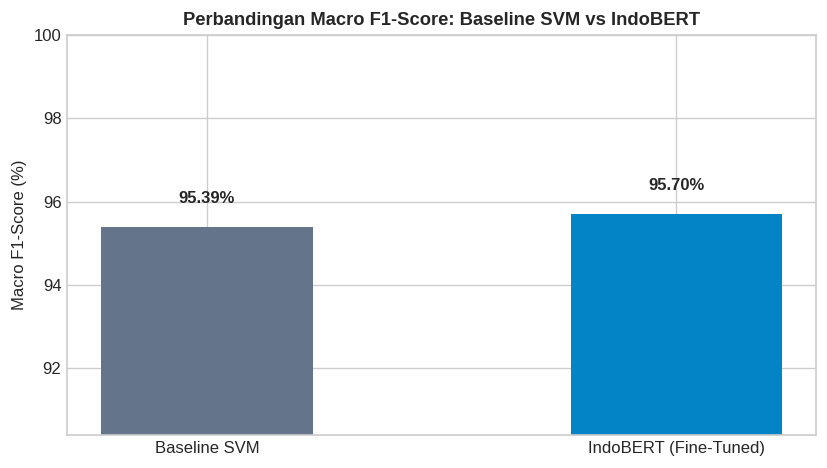

In [ ]:
# 4. Tabel Ringkasan Komparasi Kinerja untuk Bab 4 Skripsi
selisih_acc = (indobert_acc - svm_acc) * 100
selisih_f1 = (indobert_macro_f1 - svm_macro_f1) * 100

comparison_data = {
    'Metrik Pengujian': [
        'Akurasi Global',
        'Macro F1-Score (Evaluasi Utama)',
        'Weighted F1-Score',
        'Rata-rata Latensi Inferensi',
        'Kebutuhan Sumber Daya Komputasi'
    ],
    'Baseline (Linear SVM + TF-IDF)': [
        f"{svm_acc*100:.2f}%",
        f"{svm_macro_f1*100:.2f}%",
        f"{svm_weighted_f1*100:.2f}%",
        f"{latency_svm_ms:.2f} ms / aduan",
        "Sangat Ringan (CPU)"
    ],
    'IndoBERT Transformer (Fine-Tuned)': [
        f"{indobert_acc*100:.2f}%",
        f"{indobert_macro_f1*100:.2f}%",
        f"{indobert_weighted_f1*100:.2f}%",
        f"{latency_bert_ms:.2f} ms / aduan",
        "Sedang (Akselerasi GPU Disarankan)"
    ],
    'Peningkatan / Trade-off': [
        f"{'+' if selisih_acc >= 0 else ''}{selisih_acc:.2f}%",
        f"{'+' if selisih_f1 >= 0 else ''}{selisih_f1:.2f}%",
        f"{'+' if (indobert_weighted_f1 - svm_weighted_f1) >= 0 else ''}{(indobert_weighted_f1 - svm_weighted_f1)*100:.2f}%",
        f"+{latency_bert_ms - latency_svm_ms:.2f} ms",
        "Higher Contextual Semantic Awareness"
    ]
}

comparison_df = pd.DataFrame(comparison_data)
display(comparison_df)

# Visualisasi Bar Chart Perbandingan Macro F1
plt.figure(figsize=(7, 4), dpi=120)
models = ['Baseline SVM', 'IndoBERT (Fine-Tuned)']
f1_scores = [svm_macro_f1 * 100, indobert_macro_f1 * 100]
colors = ['#64748B', '#0284C7']

bars = plt.bar(models, f1_scores, color=colors, width=0.45)
plt.title("Perbandingan Macro F1-Score: Baseline SVM vs IndoBERT", fontsize=11, fontweight='bold')
plt.ylabel("Macro F1-Score (%)")
plt.ylim([min(f1_scores) - 5, 100])

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.5, f"{yval:.2f}%", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

## 11. Purwarupa Triase Cerdas Real-Time Berbasis IndoBERT
Fungsi simulasi *end-to-end* yang menerima aduan baru dari warga, melakukan inferensi dengan IndoBERT untuk memprediksi kategori serta estimasi probabilitas kepercayaan (*confidence score*), mengintegrasikan aturan urgensi, dan menentukan dinas penanggung jawab (OPD).

In [ ]:
# Pemetaan Disposisi Organisasi Perangkat Daerah (OPD) Pemkot Makassar
DISPOSISI_OPD = {
    'Lampu Jalan': 'Dinas Perhubungan (Dishub) - UPT Lampu Jalan / PJU',
    'Drainase': 'Dinas Pekerjaan Umum (DPU) - Bidang Drainase & PSDA',
    'Pangkas/Tebang Pohon': 'Dinas Lingkungan Hidup (DLH) - Bidang Ruang Terbuka Hijau & Pertamanan',
    'Sampah': 'Dinas Lingkungan Hidup (DLH) - Bidang Pengelolaan Persampahan',
    'Jalan Rusak': 'Dinas Pekerjaan Umum (DPU) - Bidang Jalan dan Jembatan'
}

# Muat model urgensi baseline (jika tersedia)
svm_urgensi_path = os.path.join(MODEL_DIR, 'baseline_svm_urgensi.joblib')
svm_urgensi = joblib.load(svm_urgensi_path) if os.path.exists(svm_urgensi_path) else None

def sistem_triase_indobert(pesan_warga):
    model.eval()

    # 1. Tokenisasi
    inputs = tokenizer(
        pesan_warga,
        return_tensors='pt',
        truncation=True,
        max_length=128,
        padding=True
    ).to(device)

    # 2. Inferensi IndoBERT
    with torch.no_grad():
        outputs = model(**inputs)
        logits = outputs.logits
        probs = torch.softmax(logits, dim=1).cpu().numpy()[0]
        pred_idx = np.argmax(probs)
        confidence = probs[pred_idx] * 100
        kategori_pred = id2label[pred_idx]

    # 3. Prediksi Skala Urgensi
    if svm_urgensi is not None and 'tfidf_vec' in globals():
        feat = tfidf_vec.transform([pesan_warga])
        urgensi_pred = svm_urgensi.predict(feat)[0]
    else:
        # Fallback aturan leksikon heuristik
        urgensi_pred = "Tinggi" if any(w in pesan_warga.lower() for w in ['darurat', 'tumbang', 'bahaya', 'korslet', 'celaka']) else "Sedang"

    opd_tujuan = DISPOSISI_OPD.get(kategori_pred, 'Sekretariat Daerah / Pengaduan Umum')
    badge_urgensi = "🚨 [TINGGI / DARURAT]" if urgensi_pred == 'Tinggi' else ("⚠️ [SEDANG]" if urgensi_pred == 'Sedang' else "ℹ️ [RENDAH]")

    print("=" * 78)
    print("🤖 REKOMENDASI TRIASE ADUAN OTOMATIS (INDOBERT TRANSFORMER)")
    print("=" * 78)
    print(f"Pesan Warga       : \"{pesan_warga}\"")
    print(f"Kategori Terpilih : 📂 {kategori_pred} (Keyakinan: {confidence:.2f}%)")
    print(f"Skala Urgensi     : {badge_urgensi}")
    print(f"Disposisi Dinas   : 🏢 {opd_tujuan}")
    print("=" * 78 + "\n")

In [ ]:
# Pengujian Skenario Nyata Aduan Warga Makassar
aduan_uji = [
    "Tolong pak di pettarani pohon besar tumbang menimpa tiang listrik bahaya sekali warga takut lewat!",
    "Lampu jalan di jalan perintis kemerdekaan km 10 padam sudah seminggu gelap gulita rawan kecelakaan",
    "Got saluran air tersumbat di depan pasar daya air meluap kotor dan bau busuk sekali tolong dikeruk",
    "Jalanan berlubang parah di hertasning baru banyak pemotor jatuh tolong segera diaspal",
    "Sampah menumpuk di pinggir jalan btp blok m belum diangkut armada truk sampah 4 hari"
]

for aduan in aduan_uji:
    sistem_triase_indobert(aduan)

🤖 REKOMENDASI TRIASE ADUAN OTOMATIS (INDOBERT TRANSFORMER)
Pesan Warga       : "Tolong pak di pettarani pohon besar tumbang menimpa tiang listrik bahaya sekali warga takut lewat!"
Kategori Terpilih : 📂 Pangkas/Tebang Pohon (Keyakinan: 99.63%)
Skala Urgensi     : 🚨 [TINGGI / DARURAT]
Disposisi Dinas   : 🏢 Dinas Lingkungan Hidup (DLH) - Bidang Ruang Terbuka Hijau & Pertamanan

🤖 REKOMENDASI TRIASE ADUAN OTOMATIS (INDOBERT TRANSFORMER)
Pesan Warga       : "Lampu jalan di jalan perintis kemerdekaan km 10 padam sudah seminggu gelap gulita rawan kecelakaan"
Kategori Terpilih : 📂 Lampu Jalan (Keyakinan: 99.93%)
Skala Urgensi     : 🚨 [TINGGI / DARURAT]
Disposisi Dinas   : 🏢 Dinas Perhubungan (Dishub) - UPT Lampu Jalan / PJU

🤖 REKOMENDASI TRIASE ADUAN OTOMATIS (INDOBERT TRANSFORMER)
Pesan Warga       : "Got saluran air tersumbat di depan pasar daya air meluap kotor dan bau busuk sekali tolong dikeruk"
Kategori Terpilih : 📂 Drainase (Keyakinan: 99.34%)
Skala Urgensi     : ⚠️ [SEDANG]
Disposisi 

## 12. Penyimpanan Model IndoBERT & Tokenizer
Mengekspor bobot model hasil *fine-tuning* dan konfigurasi tokenizer ke dalam folder `saved_models/indobert_finetuned` agar siap diintegrasikan ke dalam arsitektur API atau aplikasi web (Streamlit / FastAPI).

In [ ]:
OUTPUT_DIR = os.path.join(DATA_DIR, 'saved_models', 'indobert_finetuned')
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f"Sedang menyimpan model dan tokenizer ke '{OUTPUT_DIR}'...")
model.save_pretrained(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)

print("✅ Model IndoBERT dan Tokenizer berhasil disimpan dengan sukses!")
print(f"📁 Lokasi File Model: {os.path.abspath(OUTPUT_DIR)}")
print("\n🏁 Modul 02 Selesai! Seluruh data empiris dan metrik evaluasi siap digunakan untuk penyusunan Bab 4 Skripsi.")

Sedang menyimpan model dan tokenizer ke './saved_models/indobert_finetuned'...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Model IndoBERT dan Tokenizer berhasil disimpan dengan sukses!
📁 Lokasi File Model: /content/saved_models/indobert_finetuned

🏁 Modul 02 Selesai! Seluruh data empiris dan metrik evaluasi siap digunakan untuk penyusunan Bab 4 Skripsi.


In [ ]:
  !zip -r indobert_finetuned.zip /content/saved_models/indobert_finetuned
from google.colab import files
files.download('indobert_finetuned.zip')


  adding: content/saved_models/indobert_finetuned/ (stored 0%)
  adding: content/saved_models/indobert_finetuned/model.safetensors (deflated 7%)
  adding: content/saved_models/indobert_finetuned/config.json (deflated 57%)
  adding: content/saved_models/indobert_finetuned/tokenizer_config.json (deflated 43%)
  adding: content/saved_models/indobert_finetuned/tokenizer.json (deflated 71%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>